# N-body solver comparison: speed and accuracy

Compares four gravity solvers on the same Plummer-sphere initial conditions:

| solver | method |
|---|---|
| `direct` | NumPy O(N²) |
| `fast_direct` | Numba O(N²) |
| `barnes_hut` | pure-Python octree + traversal |
| `fast_barnes_hut` | Python tree build, Numba traversal |

**Accuracy** is measured two ways: (1) force error against exact direct summation, which isolates the tree approximation; (2) conservation of energy, momentum, angular momentum and virial ratio under a fixed leapfrog integrator, which shows what the approximation does over time.
**Speed** is wall-clock time per force evaluation (`time.perf_counter`, Numba warmed up, best/median of several repeats).

All measurements are produced by `compare.py`; this notebook only runs it (optionally) and plots the CSVs, so results are reproducible from the command line.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- configuration -------------------------------------------------------
PACKAGE      = "myproject.gravity"   # dotted name of the package containing direct.py, barnes_hut.py, ...
PROJECT_ROOT = ".."                  # folder that contains that package (added to sys.path)
BENCH_DIR    = "."                   # folder that contains compare.py
RESULTS      = Path("results")
RUN_BENCHMARK = False                # True = (re)run the measurements from this notebook
QUICK         = True                 # True = small smoke-test settings; False = full sweep (can take a long time)
# --------------------------------------------------------------------------

for p in (PROJECT_ROOT, BENCH_DIR):
    if str(Path(p).resolve()) not in sys.path:
        sys.path.insert(0, str(Path(p).resolve()))
import compare

if RUN_BENCHMARK:
    compare.run_all(PACKAGE, out=str(RESULTS), quick=QUICK)

COLORS = {"direct": "tab:blue", "fast_direct": "tab:cyan",
          "barnes_hut": "tab:red", "fast_barnes_hut": "tab:orange"}
TREE = ["barnes_hut", "fast_barnes_hut"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Load results and machine info

In [2]:
meta     = json.loads((RESULTS / "meta.json").read_text())
sanity   = json.loads((RESULTS / "sanity.json").read_text())
force    = pd.read_csv(RESULTS / "force_error.csv")
timing   = pd.read_csv(RESULTS / "timing.csv")
split    = pd.read_csv(RESULTS / "tree_split.csv")
cons     = pd.read_csv(RESULTS / "conservation.csv")

print("Solvers:", ", ".join(meta["solvers"]))
print("Machine:", meta["machine"]["platform"], "|", meta["machine"]["cpu_count"], "CPUs")
print("Python", meta["machine"]["python"], "| NumPy", meta["machine"]["numpy"], "| Numba", meta["machine"].get("numba"),
      "| Numba threads", meta["machine"].get("numba_threads"))
cfg = meta["config"]
print(f"eps={cfg['eps']}  default theta={cfg['theta_default']}  seed={cfg['seed']}  "
      f"conservation: N={cfg['n_cons']}, dt={cfg['dt']}, steps={cfg['steps']}")

Solvers: fast_direct, fast_barnes_hut
Machine: macOS-26.6.2-arm64-arm-64bit | 8 CPUs
Python 3.12.4 | NumPy 1.26.4 | Numba 0.59.1 | Numba threads 8
eps=0.05  default theta=0.5  seed=42  conservation: N=500, dt=0.01, steps=300


## 1. Sanity checks

Solver pairs that share an algorithm must agree to roundoff, and the tree codes must converge to direct summation as θ → 0. If these fail, nothing below is trustworthy.

In [3]:
pd.Series(sanity, name="max relative force difference").to_frame()

,max relative force difference
n,5.000000e+02
direct_vs_fast_direct_max_rel,4.437676e-16
bh_vs_fast_bh_max_rel,2.460326e-15
barnes_hut_theta0.05_vs_direct_max_rel,3.434090e-05
fast_barnes_hut_theta0.05_vs_direct_max_rel,3.434090e-05


## 2. Force error vs. exact direct summation

Per-particle relative error `|a − a_ref| / |a_ref|` on one fixed snapshot. Direct solvers should sit at roundoff; the tree codes trace out the accuracy/θ tradeoff. Error is dominated by particles in low-density regions and by near-cancellation of forces near the centre, so look at the 99th percentile as well as the median.

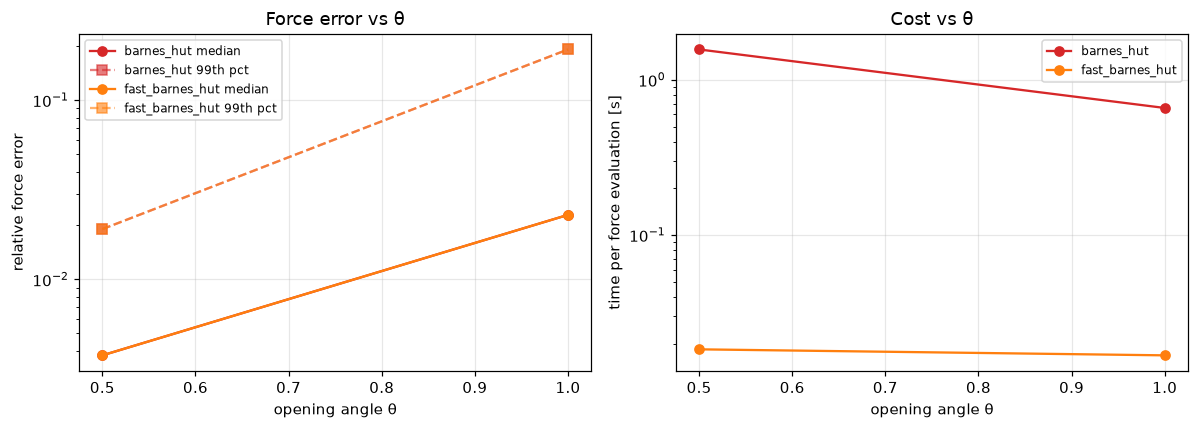

,solver,theta,n,err_median,err_p99,err_max,time_min_s
0,direct,NaN,500,0.000000,0.000000,0.000000,0.014705
1,fast_direct,NaN,500,0.000000,0.000000,0.000000,0.000928
2,barnes_hut,0.5,500,0.003769,0.019086,0.060444,1.567078
3,barnes_hut,1.0,500,0.022917,0.192006,0.387742,0.658322
4,fast_barnes_hut,0.5,500,0.003769,0.019086,0.060444,0.018373
5,fast_barnes_hut,1.0,500,0.022917,0.192006,0.387742,0.016806


In [4]:
tree_f = force[force.solver.isin(TREE)]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, g in tree_f.groupby("solver"):
    g = g.sort_values("theta")
    ax[0].plot(g.theta, g.err_median, "o-", color=COLORS[name], label=f"{name} median")
    ax[0].plot(g.theta, g.err_p99, "s--", color=COLORS[name], alpha=.6, label=f"{name} 99th pct")
ax[0].set(xlabel="opening angle θ", ylabel="relative force error", yscale="log", title="Force error vs θ")
ax[0].legend(fontsize=8)

for name, g in tree_f.groupby("solver"):
    g = g.sort_values("theta")
    ax[1].plot(g.theta, g.time_min_s, "o-", color=COLORS[name], label=name)
ax[1].set(xlabel="opening angle θ", ylabel="time per force evaluation [s]", yscale="log", title="Cost vs θ")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

force[["solver", "theta", "n", "err_median", "err_p99", "err_max", "time_min_s"]].round(6)

## 3. Speed: time vs. N

Log-log plot of best-of-repeats wall time per force evaluation. Dotted lines show ideal N² and N log N scaling for reference; the fitted slope uses the largest points of each solver. Solvers are capped at different maximum N (see `DEFAULT_MAX_N` in `compare.py`) because the pure-Python tree and the N×N×3 NumPy array do not scale.

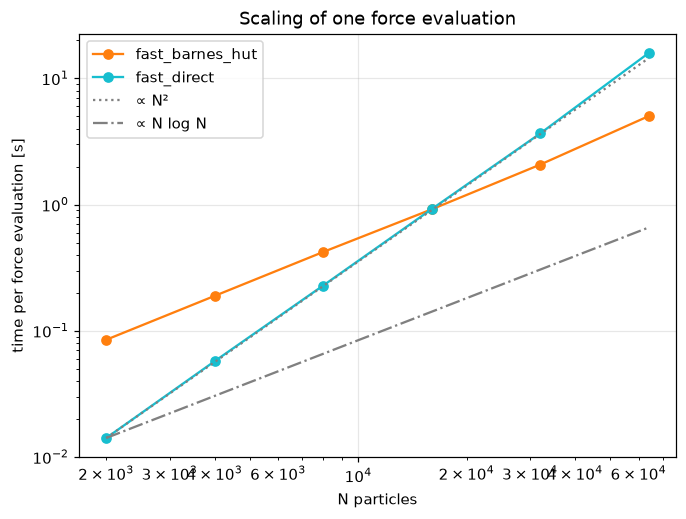

Fitted log-log slopes (largest points):
  fast_barnes_hut   1.19
  fast_direct       2.04


In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
slopes = {}
for name, g in timing.groupby("solver"):
    g = g.sort_values("n")
    ax.plot(g.n, g.time_min_s, "o-", color=COLORS[name], label=name)
    tail = g.tail(4)
    if len(tail) >= 3:
        slopes[name] = np.polyfit(np.log(tail.n), np.log(tail.time_min_s), 1)[0]

n_ref = np.array([timing.n.min(), timing.n.max()], dtype=float)
t0 = timing.time_min_s.min()
ax.plot(n_ref, t0 * (n_ref / n_ref[0])**2, ":", color="gray", label="∝ N²")
ax.plot(n_ref, t0 * (n_ref / n_ref[0]) * np.log(n_ref) / np.log(n_ref[0]), "-.", color="gray", label="∝ N log N")
ax.set(xscale="log", yscale="log", xlabel="N particles", ylabel="time per force evaluation [s]",
       title="Scaling of one force evaluation")
ax.legend()
plt.show()

print("Fitted log-log slopes (largest points):")
for k, v in slopes.items():
    print(f"  {k:16s} {v:5.2f}")

solver,fast_barnes_hut,fast_direct
n,,
2000,0.084837,0.014124
4000,0.188955,0.057393
8000,0.420949,0.228272
16000,0.916670,0.920900
32000,2.073308,3.659156
64000,5.024228,15.890558


Measured: fast_barnes_hut first beats fast_direct at N = 16000
Fitted crossover: N ~ 16,280
Slopes: {'fast_direct': 2.04, 'fast_barnes_hut': 1.19}


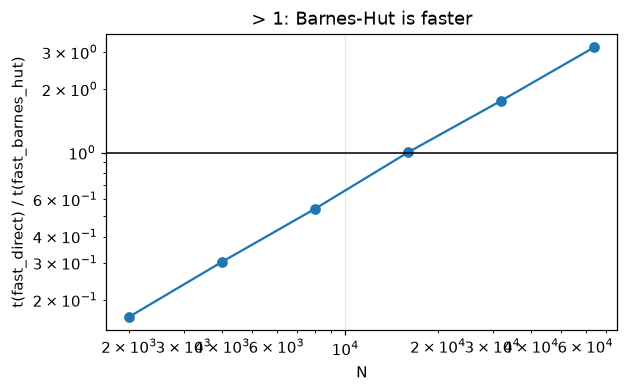

In [6]:
# Speedup relative to NumPy direct and to pure-Python Barnes-Hut at the largest N where each pair was measured
piv = timing.pivot(index="n", columns="solver", values="time_min_s")
display(piv)
for base in ("direct", "barnes_hut"):
    if base in piv:
        s = piv.drop(columns=base).rdiv(piv[base], axis=0)
        print(f"\nSpeedup vs {base} (>1 means faster than {base}):")
        display(s.dropna(how="all").round(2))

# Crossover between the two compiled solvers
print("Measured: ", end="")
if {"fast_direct", "fast_barnes_hut"} <= set(piv.columns):
    both = piv[["fast_direct", "fast_barnes_hut"]].dropna()
    win = both.index[both.fast_barnes_hut < both.fast_direct]
    print("fast_barnes_hut first beats fast_direct at N =", int(win.min()) if len(win) else "not within the measured range")

# Power-law fit t = c N^p to the largest points of each solver, solved for the intersection.
# This also works when the crossover is beyond what you measured.
rows = timing.to_dict("records")
est = compare.estimate_crossover(rows)
if est is None:
    print("Fitted curves do not cross: the tree code is not scaling better than direct yet.")
else:
    tag = " (extrapolated beyond measured N: treat as rough)" if est["extrapolated"] else ""
    print(f"Fitted crossover: N ~ {est['n_cross']:,.0f}{tag}")
    print("Slopes:", {k: round(float(v), 2) for k, v in est["slopes"].items()})

# Visual: time ratio, with the crossover at ratio = 1
if {"fast_direct", "fast_barnes_hut"} <= set(piv.columns):
    r = (piv.fast_direct / piv.fast_barnes_hut).dropna()
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.plot(r.index, r.values, "o-")
    ax.axhline(1, color="k", lw=1)
    ax.set(xscale="log", yscale="log", xlabel="N", ylabel="t(fast_direct) / t(fast_barnes_hut)",
           title="> 1: Barnes-Hut is faster")
    plt.show()

## 4. Where does Barnes-Hut spend its time?

Only `_traverse` is compiled in `fast_barnes_hut`; tree construction and flattening (`build_tree`, `packed_tree`) are still Python. At large N the Python build can become the bottleneck once traversal is fast, which tells you what to optimise next. The pack time is estimated as `packed_tree` minus one `build_tree`, so it is noisy when small.

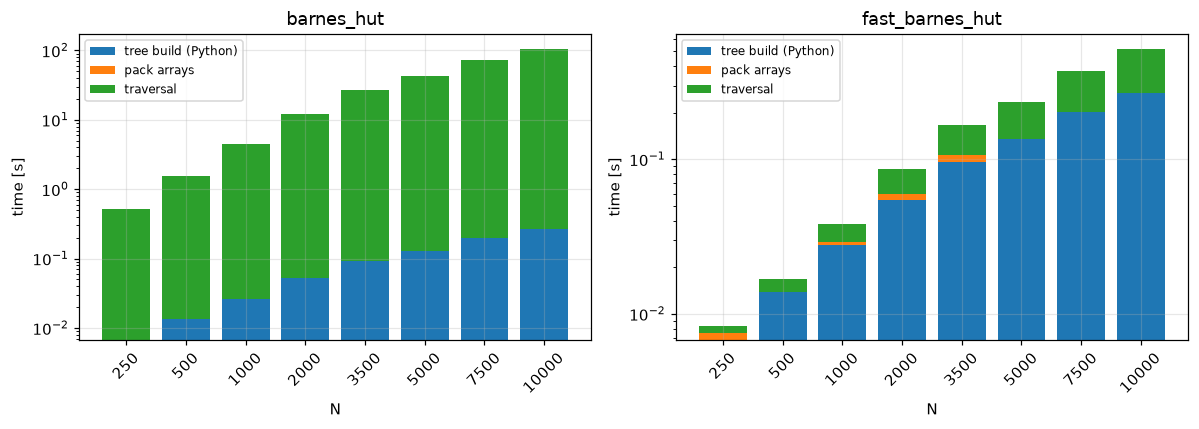

,solver,n,build_s,pack_s,traverse_s,total_s,build_frac
0,barnes_hut,250,0.0068,0.0000,0.5084,0.5152,0.0131
1,fast_barnes_hut,250,0.0068,0.0007,0.0009,0.0084,0.8102
2,barnes_hut,500,0.0136,0.0000,1.5499,1.5635,0.0087
3,fast_barnes_hut,500,0.0139,0.0000,0.0029,0.0169,0.8257
4,barnes_hut,1000,0.0264,0.0000,4.3986,4.4250,0.0060
5,fast_barnes_hut,1000,0.0277,0.0013,0.0090,0.0381,0.7272
6,barnes_hut,2000,0.0533,0.0000,12.1309,12.1842,0.0044
7,fast_barnes_hut,2000,0.0542,0.0052,0.0266,0.0860,0.6303
8,barnes_hut,3500,0.0933,0.0000,26.5941,26.6874,0.0035
9,fast_barnes_hut,3500,0.0956,0.0117,0.0595,0.1668,0.5735


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, name in zip(axes, TREE):
    g = split[split.solver == name].sort_values("n")
    if g.empty:
        ax.set_visible(False); continue
    x = np.arange(len(g))
    ax.bar(x, g.build_s, label="tree build (Python)")
    ax.bar(x, g.pack_s, bottom=g.build_s, label="pack arrays")
    ax.bar(x, g.traverse_s, bottom=g.build_s + g.pack_s, label="traversal")
    ax.set_xticks(x); ax.set_xticklabels(g.n.astype(int), rotation=45)
    ax.set(xlabel="N", ylabel="time [s]", title=name, yscale="log")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

split.assign(build_frac=lambda d: d.build_s / d.total_s).round(4)

## 5. Conservation over time

Identical initial conditions, identical kick-drift-kick leapfrog and timestep for every solver, so differences come from the force calculation. Energy is always evaluated exactly (softened potential, direct sum) and excluded from timings.

* **Relative energy error** `(E(t) − E(0)) / |E(0)|`: combined integrator and force error. The direct solvers show the integrator floor.
* **Momentum drift**: pairwise-symmetric forces conserve momentum exactly; Barnes-Hut forces are not symmetric (Newton's third law is violated), so any drift here is purely from the tree approximation.
* **Virial ratio** `2K/|U|` and **half-mass radius**: statistical checks that the cluster stays in equilibrium. Individual trajectories are not compared because the system is chaotic.

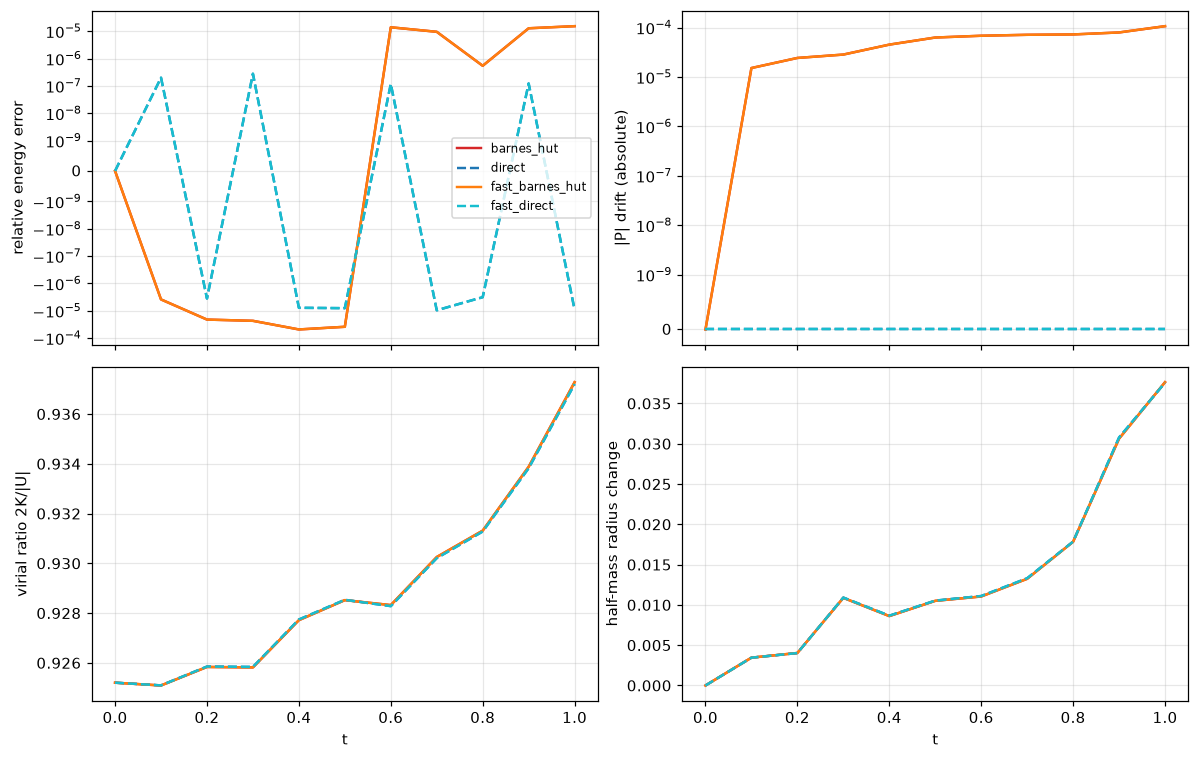

,max_abs_dE_rel,final_p_drift,final_dL_rel,wall_total_s,wall_force_s
solver,,,,,
barnes_hut,0.000048,1.067109e-04,7.232973e-05,35.382041,35.377630
direct,0.000010,1.048404e-17,-8.035133e-16,0.205410,0.201386
fast_barnes_hut,0.000048,1.067109e-04,7.232973e-05,0.707257,0.702638
fast_direct,0.000010,6.073271e-18,-8.035133e-16,0.017496,0.014264


In [8]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
panels = [("dE_rel", "relative energy error", "symlog"),
          ("p_drift", "|P| drift (absolute)", "symlog"),
          ("virial", "virial ratio 2K/|U|", "linear"),
          ("dr_half_rel", "half-mass radius change", "linear")]
for a, (col, label, scale) in zip(ax.ravel(), panels):
    for name, g in cons.groupby("solver"):
        a.plot(g.t, g[col], color=COLORS[name], label=name,
               ls="-" if name in TREE else "--", lw=1.6)
    a.set(ylabel=label, yscale=scale)
    if scale == "symlog":
        a.set_yscale("symlog", linthresh=1e-9)
ax[1, 0].set_xlabel("t"); ax[1, 1].set_xlabel("t")
ax[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

summary = cons.groupby("solver").agg(
    max_abs_dE_rel=("dE_rel", lambda s: s.abs().max()),
    final_p_drift=("p_drift", "last"),
    final_dL_rel=("dL_rel", "last"),
    wall_total_s=("wall_total_s", "first"),
    wall_force_s=("wall_force_s", "first"))
summary

## 6. Accuracy vs. cost (Pareto view)

Each point is one solver (and one θ for the tree codes) on the same snapshot. Down and to the left is better: lower error for less time. Points that no other point beats in both axes form the Pareto front.

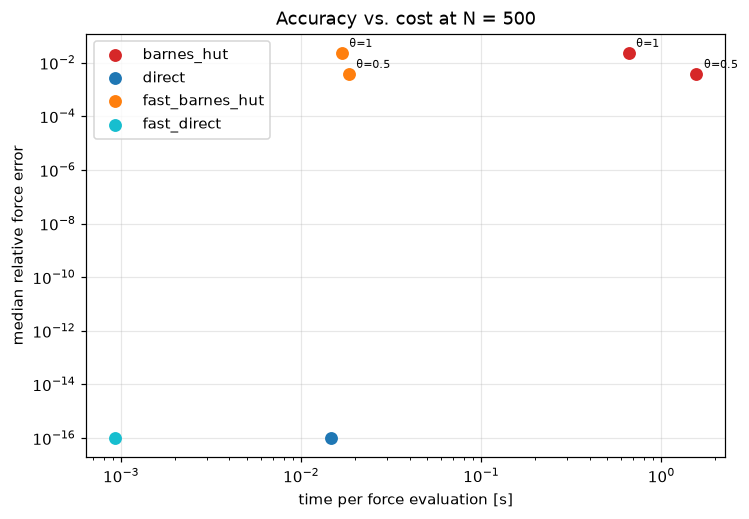

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 5))
plot_df = force.copy()
# the direct solvers have roundoff-level error; floor it so it shows on a log axis
plot_df["err_plot"] = plot_df.err_median.clip(lower=1e-16)
for name, g in plot_df.groupby("solver"):
    ax.scatter(g.time_min_s, g.err_plot, color=COLORS[name], s=55, label=name, zorder=3)
    for _, r in g.iterrows():
        if name in TREE:
            ax.annotate(f"θ={r.theta:g}", (r.time_min_s, r.err_plot), textcoords="offset points",
                        xytext=(5, 4), fontsize=7)
ax.set(xscale="log", yscale="log", xlabel="time per force evaluation [s]",
       ylabel="median relative force error",
       title=f"Accuracy vs. cost at N = {int(force.n.iloc[0])}")
ax.legend()
plt.show()

## 7. Reading the results

Use these questions when interpreting your own numbers:

* **Does θ = 0.5 give acceptable force error?** Compare median and 99th-percentile error in section 2. Typical production values are 10⁻³ to 10⁻².
* **Where is the crossover?** Section 3 shows the N above which tree codes beat direct summation. Compiled direct summation can win to surprisingly large N because it has no tree overhead.
* **Is `fast_barnes_hut` limited by traversal or by the Python build?** Section 4. If build dominates, vectorise or compile the tree construction next.
* **Is the energy drift from the integrator or from the tree?** If tree and direct energy errors are similar, the integrator (dt, softening) dominates and a smaller θ will not help. If trees are clearly worse and the momentum drift is non-zero, the force approximation is the cause.
* **Caveats:** one random realisation (seed in `meta.json`), single-threaded Numba, and the conservation run is short. For stronger claims, repeat with several seeds and longer runs.